Intelligent Multi-Class Natural Language Text Sentiment Classifier

Install libraries

In [1]:
!pip install nltk scikit-learn pandas matplotlib seaborn

Import libraries

In [2]:
import pandas as pd
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


Download NLTK resources

In [3]:
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("NLTK resources downloaded!")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


NLTK resources downloaded!


Load real dataset

In [12]:
# Load real sentiment dataset
url = "https://raw.githubusercontent.com/satyajeetkrjha/kaggle-Twitter-US-Airline-Sentiment-/master/Tweets.csv"

df = pd.read_csv(url)

# Select required columns
df = df[['text', 'airline_sentiment']]

# Rename sentiment column
df = df.rename(columns={
    'airline_sentiment': 'sentiment'
})

# Remove missing values
df = df.dropna()

# Display dataset
print("Dataset shape:", df.shape)

df.head()

Dataset shape: (14640, 2)


,text,sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,positive
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative


Check sentiment distribution

sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


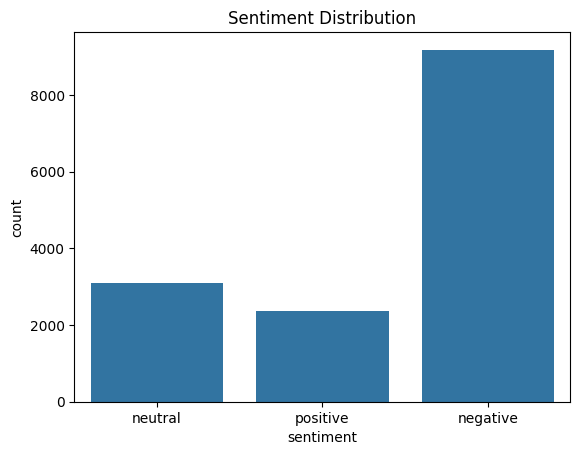

In [13]:
print(df['sentiment'].value_counts())

sns.countplot(data=df, x='sentiment')
plt.title("Sentiment Distribution")
plt.show()

In [14]:
# Text preprocessing

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)

    words = text.split()

    cleaned_words = []

    for word in words:
        if word not in stop_words:
            cleaned_words.append(lemmatizer.lemmatize(word))

    return ' '.join(cleaned_words)

df['clean_text'] = df['text'].apply(preprocess_text)

df[['text', 'clean_text', 'sentiment']].head()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


,text,clean_text,sentiment
0,@VirginAmerica What @dhepburn said.,virginamerica dhepburn said,neutral
1,@VirginAmerica plus you've added commercials t...,virginamerica plus added commercial experience...,positive
2,@VirginAmerica I didn't today... Must mean I n...,virginamerica today must mean need take anothe...,neutral
3,@VirginAmerica it's really aggressive to blast...,virginamerica really aggressive blast obnoxiou...,negative
4,@VirginAmerica and it's a really big bad thing...,virginamerica really big bad thing,negative


In [15]:
# Separate text and sentiment labels

X = df['clean_text']
y = df['sentiment']

# Split dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 11712
Testing samples: 2928


In [16]:
# Initialize TF-IDF Vectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

# Convert training text into numerical features

X_train_tfidf = tfidf.fit_transform(X_train)

# Convert testing text

X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (11712, 10000)
Testing TF-IDF shape: (2928, 10000)


In [17]:
# Initialize Logistic Regression model

model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

# Train the model

model.fit(X_train_tfidf, y_train)

print("Sentiment classification model trained successfully!")

Sentiment classification model trained successfully!


In [18]:
# Predict sentiment for test data

y_pred = model.predict(X_test_tfidf)

# Calculate accuracy

accuracy = accuracy_score(y_test, y_pred)

# Calculate macro F1-score

f1 = f1_score(y_test, y_pred, average='macro')

print("Model Accuracy:", round(accuracy, 4))
print("Macro F1-Score:", round(f1, 4))

# Classification report

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Model Accuracy: 0.762
Macro F1-Score: 0.7153

Classification Report:

              precision    recall  f1-score   support

    negative       0.90      0.80      0.84      1835
     neutral       0.54      0.70      0.61       620
    positive       0.68      0.71      0.69       473

    accuracy                           0.76      2928
   macro avg       0.70      0.74      0.72      2928
weighted avg       0.79      0.76      0.77      2928



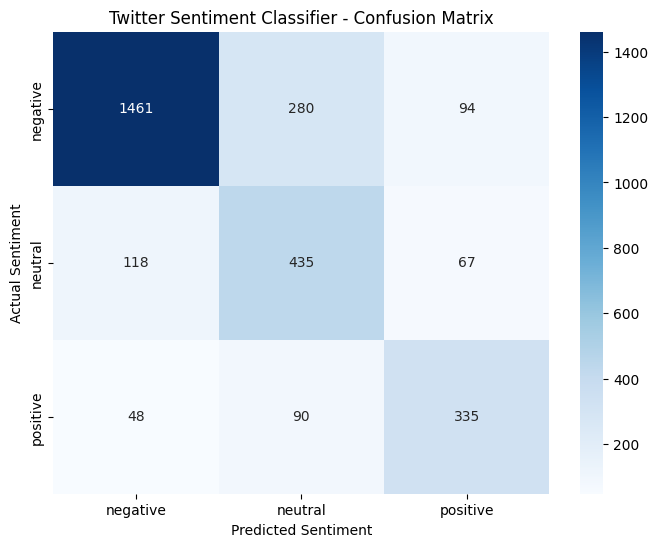

In [19]:
labels = ['negative', 'neutral', 'positive']

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Twitter Sentiment Classifier - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()

In [22]:
# Step 20: Test the model with custom tweets

def predict_sentiment(text):
    cleaned_text = preprocess_text(text)

    text_vector = tfidf.transform([cleaned_text])

    prediction = model.predict(text_vector)

    return prediction[0]


custom_tweets = [
    "I absolutely love this airline, the service is amazing!",
    "My flight was delayed and the staff were very rude.",
    "My flight is scheduled for tomorrow morning."
]

for tweet in custom_tweets:

    result = predict_sentiment(tweet)

    print("Tweet:", tweet)
    print("Predicted Sentiment:", result)
    print("-" * 50)

Tweet: I absolutely love this airline, the service is amazing!
Predicted Sentiment: positive
--------------------------------------------------
Tweet: My flight was delayed and the staff were very rude.
Predicted Sentiment: negative
--------------------------------------------------
Tweet: My flight is scheduled for tomorrow morning.
Predicted Sentiment: neutral
--------------------------------------------------


In [23]:
import joblib

joblib.dump(model, 'sentiment_model.pkl')
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

print("Model and TF-IDF vectorizer saved successfully!")

Model and TF-IDF vectorizer saved successfully!


In [24]:
from google.colab import files

files.download('sentiment_model.pkl')
files.download('tfidf_vectorizer.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>